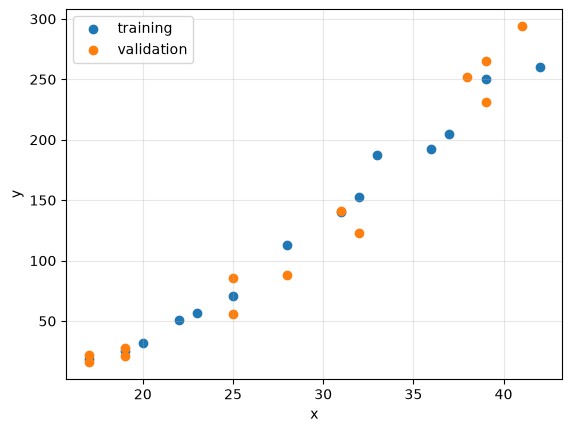

In [1]:
import numpy as np
import matplotlib.pyplot as plt

xtrain = np.array([17, 19, 20, 22, 23, 25, 28, 31, 32, 33, 36, 37, 39, 42], dtype=float)
ytrain = np.array([19, 25, 32, 51, 57, 71, 113, 140, 153, 187, 192, 205, 250, 260], dtype=float)
xvalid = np.array([17, 17, 19, 19, 25, 25, 28, 31, 32, 38, 39, 39, 41], dtype=float)
yvalid = np.array([16, 22, 28, 21, 56, 86, 88, 141, 123, 252, 231, 265, 294], dtype=float)

plt.scatter(xtrain, ytrain, label="training")
plt.scatter(xvalid, yvalid, label="validation")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


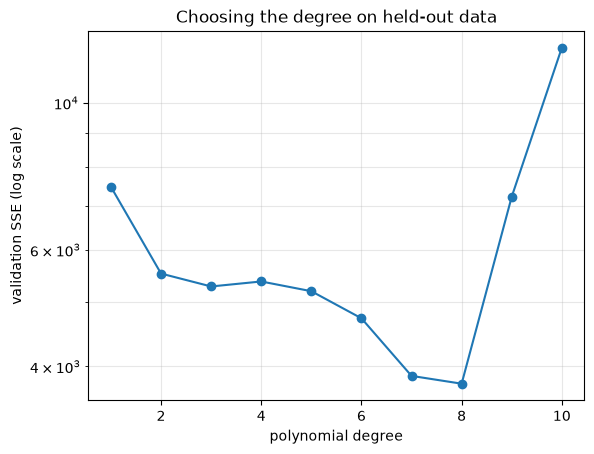

In [2]:
degrees = np.arange(0, 11)  # more parameters than data points adds no information
validation_sse = []

for degree in degrees:
    model = np.polynomial.Chebyshev.fit(xtrain, ytrain, degree)
    prediction = model(xvalid)
    validation_sse.append(np.sum((yvalid - prediction) ** 2))

plt.semilogy(degrees[1:], validation_sse[1:], "o-")
plt.xlabel("polynomial degree")
plt.ylabel("validation SSE (log scale)")
plt.title("Choosing the degree on held-out data")
plt.grid(which="both", alpha=0.3)
plt.show()


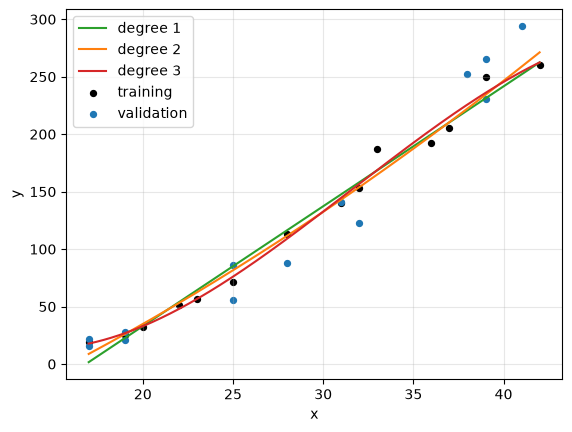

In [3]:
xplot = np.linspace(17, 42, 300)
for degree, color in ((1, "tab:green"), (2, "tab:orange"), (3, "tab:red")):
    model = np.polynomial.Chebyshev.fit(xtrain, ytrain, degree)
    plt.plot(xplot, model(xplot), color=color, label=f"degree {degree}")

plt.scatter(xtrain, ytrain, label="training", color="black", s=18)
plt.scatter(xvalid, yvalid, label="validation", color="tab:blue", s=18)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


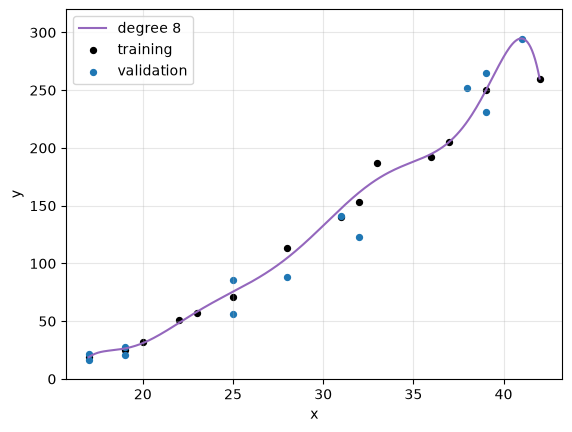

In [4]:
# A high-degree fit illustrates overfitting: it follows the training points
# but oscillates between them.
model8 = np.polynomial.Chebyshev.fit(xtrain, ytrain, 8)
plt.plot(xplot, model8(xplot), color="tab:purple", label="degree 8")
plt.scatter(xtrain, ytrain, label="training", color="black", s=18)
plt.scatter(xvalid, yvalid, label="validation", color="tab:blue", s=18)
plt.ylim(0, 320)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
